In [ ]:
pip install scikit-learn

In [ ]:
import json
from pathlib import Path
from sklearn.model_selection import train_test_split

# Configuration
INPUT_FILE = "Data_train.json"
OUTPUT_DIR = Path("datasets")
RANDOM_STATE = 42

# 1. Charger les données
with open(INPUT_FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

# Récupérer la liste des exemples
examples = data["examples"]
print(f"Nombre total d'exemples : {len(examples)}")

# 2. Séparer 20 % pour le test
train_val, test = train_test_split(
    examples,
    test_size=0.20,
    random_state=RANDOM_STATE,
    shuffle=True
)

# 3. Séparer les 80 % restants en train et validation
# 12,5 % de 80 % = 10 % du dataset total
train, validation = train_test_split(
    train_val,
    test_size=0.125,
    random_state=RANDOM_STATE,
    shuffle=True
)

# 4. Créer le dossier de sortie
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 5. Enregistrer les trois ensembles
datasets = {
    "train": train,
    "validation": validation,
    "test": test
}

for name, dataset in datasets.items():
    output_file = OUTPUT_DIR / f"{name}.json"

    # On conserve la structure d'origine du dictionnaire de métadonnées pour chaque fichier de sortie
    output_data = {
        "format": data.get("format", ""),
        "description": data.get("description", ""),
        "examples": dataset
    }

    with open(output_file, "w", encoding="utf-8") as f:
        json.dump(output_data, f, ensure_ascii=False, indent=2)

    print(f"{name}: {len(dataset)} exemples -> {output_file}")

print("Répartition terminée.")

Nombre total d'exemples : 392
train: 273 exemples -> datasets/train.json
validation: 40 exemples -> datasets/validation.json
test: 79 exemples -> datasets/test.json
Répartition terminée.


Le script crée un dossier `datasets/` contenant `train.json`, `validation.json` et `test.json`.

In [ ]:
from collections import Counter

for name, dataset in datasets.items():
    print(f"\n{name.upper()} — {len(dataset)} exemples")
    categories = [item.get("type", "sans type") for item in dataset]
    for category, count in Counter(categories).most_common():
        percentage = (count / len(dataset)) * 100
        print(f"  - {category}: {count} ({percentage:.1f}%)")


TRAIN — 273 exemples
  - action.valide: 102 (37.4%)
  - exploration: 52 (19.0%)
  - action.invalide: 44 (16.1%)
  - action.incohérente: 24 (8.8%)
  - action.ambiguë: 9 (3.3%)
  - fin: 6 (2.2%)
  - début: 6 (2.2%)
  - énonciation: 6 (2.2%)
  - fin - victoire: 3 (1.1%)
  - fin - défaite: 2 (0.7%)
  - action.ambiguë - intention générale: 1 (0.4%)
  - action.valide - reformulation détaillée: 1 (0.4%)
  - action.incohérente - changement brutal d'intention: 1 (0.4%)
  - action.incohérente - action nouvelle: 1 (0.4%)
  - action.valide - reformulation: 1 (0.4%)
  - action.ambiguë - absence d'intention: 1 (0.4%)
  - action.incohérente - rupture de continuité: 1 (0.4%)
  - action.incohérente - après action préparatoire: 1 (0.4%)
  - action.valide - intention de combat: 1 (0.4%)
  - fin - choix moral: 1 (0.4%)
  - action.ambiguë - plusieurs intentions possibles: 1 (0.4%)
  - action.incohérente - interprétation excessive: 1 (0.4%)
  - action.ambiguë - choix du moyen: 1 (0.4%)
  - action.invalide 

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

# Fonction pour nettoyer et regrouper les catégories
def clean_category(cat):
    if not cat:
        return "sans type"
    # On sépare sur le premier tiret ou espace pour ne garder que la catégorie principale
    # (ex: "action.incohérente - changement brutal" -> "action.incohérente")
    cleaned = cat.split(" -")[0].split(" -")[0].strip()
    return cleaned

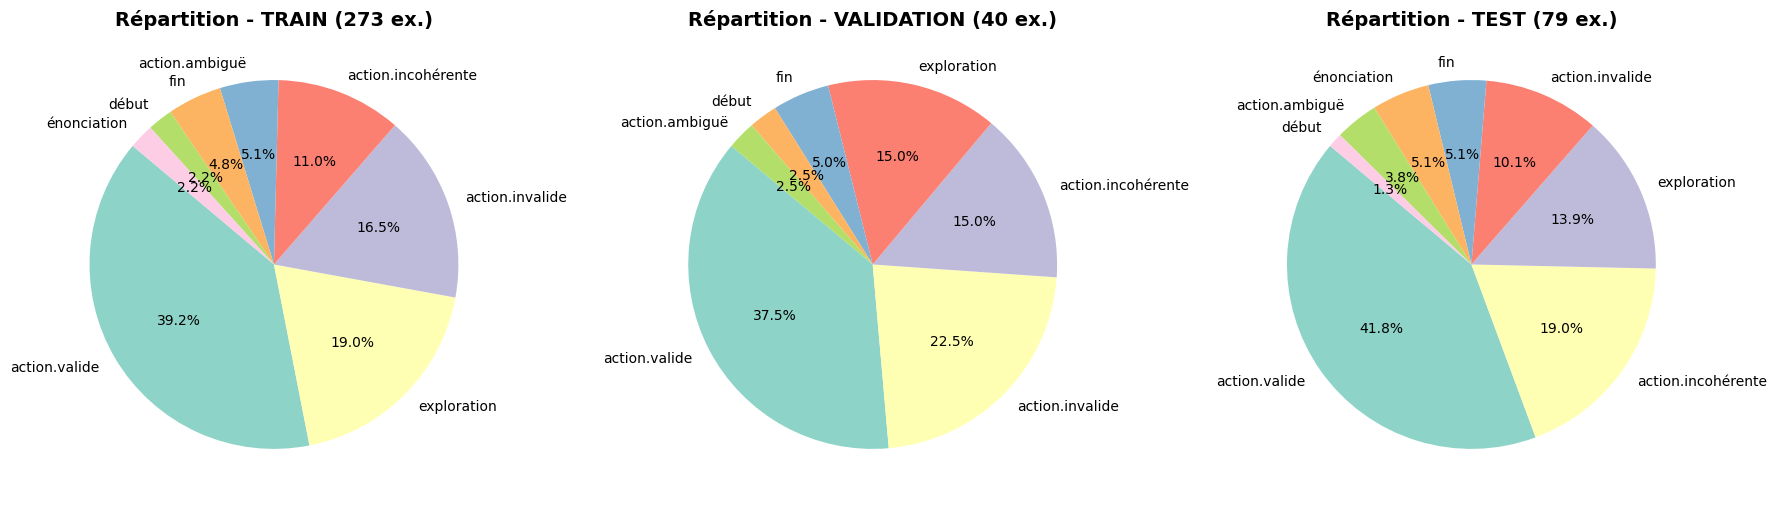

In [ ]:
# Configuration de la figure matplotlib avec 3 sous-graphiques (1 ligne, 3 colonnes)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, (name, dataset) in enumerate(datasets.items()):
    # Nettoyage et comptage
    categories = [clean_category(item.get("type", "sans type")) for item in dataset]
    counter = Counter(categories)

    # Tri des données pour un affichage propre
    labels, values = zip(*counter.most_common())

    # Création du camembert pour l'ensemble courant
    axes[i].pie(
        values,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=plt.cm.Set3.colors
    )
    axes[i].set_title(f"Répartition - {name.upper()} ({len(dataset)} ex.)", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
for name, dataset in datasets.items():
    print(f"\n{name.upper()} — {len(dataset)} exemples")
    categories = [clean_category(item.get("type", "sans type")) for item in dataset]
    counter = Counter(categories)
    for category, count in counter.most_common():
        percentage = (count / len(dataset)) * 100
        print(f"  - {category}: {count} ({percentage:.1f}%)")



TRAIN — 273 exemples
  - action.valide: 107 (39.2%)
  - exploration: 52 (19.0%)
  - action.invalide: 45 (16.5%)
  - action.incohérente: 30 (11.0%)
  - action.ambiguë: 14 (5.1%)
  - fin: 13 (4.8%)
  - début: 6 (2.2%)
  - énonciation: 6 (2.2%)

VALIDATION — 40 exemples
  - action.valide: 15 (37.5%)
  - action.invalide: 9 (22.5%)
  - action.incohérente: 6 (15.0%)
  - exploration: 6 (15.0%)
  - fin: 2 (5.0%)
  - début: 1 (2.5%)
  - action.ambiguë: 1 (2.5%)

TEST — 79 exemples
  - action.valide: 33 (41.8%)
  - action.incohérente: 15 (19.0%)
  - exploration: 11 (13.9%)
  - action.invalide: 8 (10.1%)
  - fin: 4 (5.1%)
  - énonciation: 4 (5.1%)
  - action.ambiguë: 3 (3.8%)
  - début: 1 (1.3%)


On peut voir la répartition des exemples en foction de leurs types dans chacun des 3 ensembles.